In [1]:
import os, sys, json, time, warnings, textwrap
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import Descriptors, MACCSkeys, rdFingerprintGenerator, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Descriptors import MoleculeDescriptors
RDLogger.DisableLog("rdApp.*")

from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.linear_model import BayesianRidge, RidgeCV, ElasticNet
from sklearn.svm import SVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import (GradientBoostingRegressor, RandomForestRegressor,
                              ExtraTreesRegressor, StackingRegressor)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, GroupKFold, StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25})

print("python     :", sys.version.split()[0])
import sklearn, rdkit
print("rdkit      :", rdkit.__version__)
print("scikit-learn:", sklearn.__version__)

python     : 3.11.18
rdkit      : 2026.03.6
scikit-learn: 1.9.1


In [2]:
CSV_LOCAL = "/data/Zira/Chemprop_Kd_Mann/USP5_mann_53_Kd.csv"

df = pd.read_csv(CSV_LOCAL)
print("Dibaca dari file lokal:", CSV_LOCAL)

df.columns = ["chembl_id", "smiles", "pKd"]
print("Dimensi:", df.shape)
df.head()

Dibaca dari file lokal: /data/Zira/Chemprop_Kd_Mann/USP5_mann_53_Kd.csv
Dimensi: (53, 3)


,chembl_id,smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
2,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
3,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373
4,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,3.823909


In [3]:
# Validasi struktur & kanonikalisasi SMILES
mols, bad = [], []
for i, s in enumerate(df.smiles):
    m = Chem.MolFromSmiles(s)
    if m is None:
        bad.append(i)
    mols.append(m)

print(f"SMILES valid : {sum(m is not None for m in mols)}/{len(mols)}")
print(f"SMILES gagal : {len(bad)}")

df["canonical_smiles"] = [Chem.MolToSmiles(m) if m else None for m in mols]
dup = df.canonical_smiles.duplicated().sum()
print(f"Duplikat canonical SMILES: {dup}   (harus 0 — konsisten dengan audit KNIME)")

y = df.pKd.values.astype(float)
print(f"\nStatistik target pKd  n={len(y)}")
print(f"  min {y.min():.4f} | Q1 {np.quantile(y,.25):.4f} | median {np.median(y):.4f} "
      f"| Q3 {np.quantile(y,.75):.4f} | max {y.max():.4f}")
print(f"  mean {y.mean():.4f} | sd {y.std(ddof=1):.4f} | rentang {y.max()-y.min():.4f}")
print(f"  jumlah senyawa pKd > 5 : {(y>5).sum()}  ({(y>5).mean()*100:.1f}%)")

SMILES valid : 53/53
SMILES gagal : 0
Duplikat canonical SMILES: 0   (harus 0 — konsisten dengan audit KNIME)

Statistik target pKd  n=53
  min 3.5686 | Q1 4.0605 | median 4.3768 | Q3 4.6778 | max 5.5528
  mean 4.3942 | sd 0.4649 | rentang 1.9842
  jumlah senyawa pKd > 5 : 7  (13.2%)


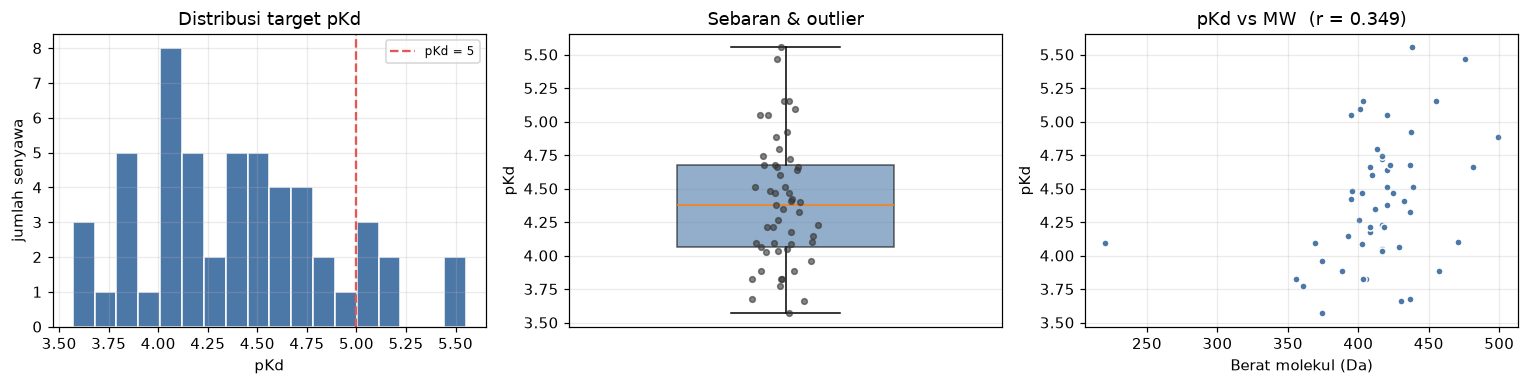

Korelasi Pearson MW–pKd: 0.3495  -> ada tren ukuran molekul


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))

ax[0].hist(y, bins=18, color="#4C78A8", edgecolor="white")
ax[0].axvline(5, ls="--", c="#E45756", lw=1.5, label="pKd = 5")
ax[0].set_xlabel("pKd"); ax[0].set_ylabel("jumlah senyawa")
ax[0].set_title("Distribusi target pKd"); ax[0].legend(fontsize=8)

ax[1].boxplot(y, vert=True, widths=0.5, patch_artist=True,
              boxprops=dict(facecolor="#4C78A8", alpha=.6))
ax[1].scatter(np.random.normal(1, .04, len(y)), y, s=14, c="#333", alpha=.6, zorder=3)
ax[1].set_ylabel("pKd"); ax[1].set_title("Sebaran & outlier"); ax[1].set_xticks([])

mw  = np.array([Descriptors.MolWt(m) for m in mols])
ax[2].scatter(mw, y, s=22, c="#4C78A8", edgecolor="white")
ax[2].set_xlabel("Berat molekul (Da)"); ax[2].set_ylabel("pKd")
r_mw = pearsonr(mw, y)[0]
ax[2].set_title(f"pKd vs MW  (r = {r_mw:.3f})")
plt.tight_layout(); plt.show()

print(f"Korelasi Pearson MW–pKd: {r_mw:.4f}  -> "
      f"{'ada tren ukuran molekul' if abs(r_mw)>0.3 else 'ukuran molekul saja tidak cukup'}")

In [6]:
# Scaffold Bemis-Murcko: dasar protokol evaluasi paling ketat
def murcko(smiles_list):
    out = []
    for s in smiles_list:
        m = Chem.MolFromSmiles(s)
        sc = MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=False)
        out.append(sc if sc else s)
    return np.array(out)

scaf = murcko(df.canonical_smiles)
df["scaffold"] = scaf
vc = pd.Series(scaf).value_counts()

print(f"Jumlah scaffold unik : {len(vc)} dari {len(scaf)} senyawa")
print(f"Scaffold singleton   : {(vc==1).sum()}")
print(f"Scaffold terbesar    : {vc.iloc[0]} senyawa ({vc.iloc[0]/len(scaf)*100:.1f}% dataset)")
print("\n5 scaffold terbanyak:")
for s, c in vc.head(5).items():
    print(f"  n={c:>3}  {s}")

Jumlah scaffold unik : 25 dari 53 senyawa
Scaffold singleton   : 21
Scaffold terbesar    : 23 senyawa (43.4% dataset)

5 scaffold terbanyak:
  n= 23  O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1
  n=  3  O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1
  n=  3  O=S(=O)(c1cccs1)N1CCC(c2ccccc2)CC1
  n=  3  O=S(=O)(c1ccccc1)N1CCC(N2CCCC2)CC1
  n=  1  O=C1Cc2ccccc2N1C1CCN(S(=O)(=O)c2ccccc2)CC1


In [7]:
t0 = time.time()

# --- Blok 1: deskriptor 2D RDKit ---
desc_names = [d[0] for d in Descriptors._descList]
calc = MoleculeDescriptors.MolecularDescriptorCalculator(desc_names)
DESC = np.array([calc.CalcDescriptors(m) for m in mols], dtype=float)

# --- Blok 2: Morgan count fingerprint r=2, 1024 bit ---
mgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
MORGAN = np.array([mgen.GetCountFingerprintAsNumPy(m) for m in mols], dtype=float)

# --- Blok 3: MACCS keys ---
MACCS = np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in mols], dtype=float)

# Bersihkan nilai tak hingga pada deskriptor (beberapa deskriptor RDKit bisa NaN/Inf)
n_nan = int(np.isnan(DESC).sum()); n_inf = int(np.isinf(DESC).sum())
DESC = np.nan_to_num(DESC, nan=0.0, posinf=0.0, neginf=0.0)

print(f"DESC   : {DESC.shape}   (NaN diganti: {n_nan}, Inf diganti: {n_inf})")
print(f"MORGAN : {MORGAN.shape}   bit aktif  : {(MORGAN.sum(0)>0).sum()}/1024")
print(f"MACCS  : {MACCS.shape}    key aktif  : {(MACCS.sum(0)>0).sum()}/167")
print(f"\nWaktu featurization: {time.time()-t0:.1f} s")

DESC   : (53, 217)   (NaN diganti: 8, Inf diganti: 0)
MORGAN : (53, 1024)   bit aktif  : 299/1024
MACCS  : (53, 167)    key aktif  : 113/167

Waktu featurization: 0.6 s


In [8]:
# Matriks gabungan + indeks blok (agar setiap model bisa memilih bloknya sendiri)
X = np.hstack([DESC, MORGAN, MACCS])
nD, nM = DESC.shape[1], MORGAN.shape[1]

IDX_DESC   = np.arange(nD)
IDX_MORGAN = np.arange(nD, nD + nM)
IDX_MACCS  = np.arange(nD + nM, X.shape[1])
IDX_FPMA   = np.concatenate([IDX_MORGAN, IDX_MACCS])   # fingerprint + MACCS
IDX_DESCFP = np.concatenate([IDX_DESC,   IDX_MORGAN])  # deskriptor + fingerprint

print(f"X gabungan: {X.shape}")
print(f"  DESC            : kolom {IDX_DESC[0]}..{IDX_DESC[-1]}")
print(f"  MORGAN          : kolom {IDX_MORGAN[0]}..{IDX_MORGAN[-1]}")
print(f"  MACCS           : kolom {IDX_MACCS[0]}..{IDX_MACCS[-1]}")
print(f"  rasio fitur:sampel = {X.shape[1]}:{X.shape[0]} = {X.shape[1]/X.shape[0]:.0f}:1  "
      f"-> regularisasi wajib, bukan opsional")

X gabungan: (53, 1408)
  DESC            : kolom 0..216
  MORGAN          : kolom 217..1240
  MACCS           : kolom 1241..1407
  rasio fitur:sampel = 1408:53 = 27:1  -> regularisasi wajib, bukan opsional


In [9]:
RUN_SCREENING = False   # ubah ke True untuk mereproduksi screening penuh

def make_pre(k=None):
    """Praproses: imputasi -> buang fitur konstan -> (opsional) seleksi k terbaik -> standardisasi."""
    steps = [("imp", SimpleImputer(strategy="median")),
             ("vt",  VarianceThreshold(0.0))]
    if k:
        steps.append(("sel", SelectKBest(f_regression, k=k)))
    steps.append(("sc", StandardScaler()))
    return steps

class BlockSelector(BaseEstimator, TransformerMixin):
    """
    Transformer pemilih kolom blok fitur.

    Ditulis sebagai kelas (bukan FunctionTransformer dengan lambda) agar model
    final dapat di-pickle/di-joblib.dump tanpa error.
    """
    def __init__(self, idx):
        self.idx = idx
    def fit(self, Xm, ym=None):
        return self
    def transform(self, Xm):
        return np.asarray(Xm)[:, self.idx]

def pick(idx):
    return BlockSelector(idx)

def make_pipe(idx, model, k=None):
    return Pipeline([("pick", pick(idx))] + make_pre(k) + [("m", model)])

def cv_random(estimator_factory, Xm, ym, n_repeats=5, n_splits=5, seed0=200):
    """Repeated K-Fold CV. Mengembalikan per-ulangan metrik + rata-rata prediksi OOF."""
    recs, oofs = [], []
    for rep in range(n_repeats):
        cv = KFold(n_splits, shuffle=True, random_state=seed0 + rep)
        p = np.zeros(len(ym))
        for tr, te in cv.split(Xm):
            mdl = estimator_factory()
            mdl.fit(Xm[tr], ym[tr])
            p[te] = np.ravel(mdl.predict(Xm[te]))
        recs.append(dict(rep=rep,
                         RMSE=np.sqrt(mean_squared_error(ym, p)),
                         MAE=mean_absolute_error(ym, p),
                         R2=r2_score(ym, p)))
        oofs.append(p)
    return pd.DataFrame(recs), np.mean(oofs, axis=0)

print("Fungsi evaluasi siap. RUN_SCREENING =", RUN_SCREENING)


Fungsi evaluasi siap. RUN_SCREENING = False


In [12]:
from sklearn.linear_model import BayesianRidge, RidgeCV, ElasticNet
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import (
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    RandomForestRegressor
)
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.kernel_ridge import KernelRidge

# Memeriksa XGBoost
try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

# Memeriksa LightGBM
try:
    from lightgbm import LGBMRegressor
    HAS_LIGHTGBM = True
except ImportError:
    HAS_LIGHTGBM = False

print("XGBoost tersedia:", HAS_XGBOOST)
print("LightGBM tersedia:", HAS_LIGHTGBM)

# Daftar algoritma
MODEL_FACTORIES = {
    "BayesianRidge": lambda: BayesianRidge(),

    "PLS_6": lambda: PLSRegression(n_components=6),

    "RidgeCV": lambda: RidgeCV(
        alphas=np.logspace(-3, 3, 30)
    ),

    "ExtraTrees": lambda: ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "GradientBoosting": lambda: GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=3,
        loss="huber",
        random_state=42
    ),

    "RandomForest": lambda: RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "ElasticNet": lambda: ElasticNet(
        alpha=0.01,
        l1_ratio=0.5,
        max_iter=10000
    ),

    "GaussianProcess_RBF": lambda: GaussianProcessRegressor(
        kernel=ConstantKernel(1.0) * RBF(length_scale=1.0),
        alpha=0.01,
        normalize_y=True,
        random_state=42
    ),

    "SVR_RBF": lambda: SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    ),

    "KNN_5": lambda: KNeighborsRegressor(
        n_neighbors=5,
        weights="distance"
    ),

    "KernelRidge_RBF": lambda: KernelRidge(
        alpha=1.0,
        kernel="rbf"
    ),

    "SVR_Linear": lambda: SVR(
        kernel="linear",
        C=1.0,
        epsilon=0.1
    )
}

if HAS_XGBOOST:
    MODEL_FACTORIES["XGBoost"] = lambda: XGBRegressor(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )

if HAS_LIGHTGBM:
    MODEL_FACTORIES["LightGBM"] = lambda: LGBMRegressor(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.03,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )

print("\nJumlah algoritma tersedia:", len(MODEL_FACTORIES))
print("\nDaftar algoritma:")

for i, name in enumerate(MODEL_FACTORIES, 1):
    print(f"{i:2d}. {name}")

XGBoost tersedia: True
LightGBM tersedia: True

Jumlah algoritma tersedia: 14

Daftar algoritma:
 1. BayesianRidge
 2. PLS_6
 3. RidgeCV
 4. ExtraTrees
 5. GradientBoosting
 6. RandomForest
 7. ElasticNet
 8. GaussianProcess_RBF
 9. SVR_RBF
10. KNN_5
11. KernelRidge_RBF
12. SVR_Linear
13. XGBoost
14. LightGBM


In [13]:
# Menghapus SVR Linear dari screening utama
MODEL_FACTORIES.pop("SVR_Linear")

print("Jumlah algoritma screening:", len(MODEL_FACTORIES))
print("\nDaftar algoritma:")

for i, name in enumerate(MODEL_FACTORIES, 1):
    print(f"{i:2d}. {name}")

Jumlah algoritma screening: 13

Daftar algoritma:
 1. BayesianRidge
 2. PLS_6
 3. RidgeCV
 4. ExtraTrees
 5. GradientBoosting
 6. RandomForest
 7. ElasticNet
 8. GaussianProcess_RBF
 9. SVR_RBF
10. KNN_5
11. KernelRidge_RBF
12. XGBoost
13. LightGBM


In [15]:
FEATURE_BLOCKS = {
    "DESC": IDX_DESC,
    "MORGAN": IDX_MORGAN,
    "MACCS": IDX_MACCS,
    "MORGAN+MACCS": np.concatenate([IDX_MORGAN, IDX_MACCS]),
    "DESC+MORGAN": np.concatenate([IDX_DESC, IDX_MORGAN]),
    "DESC+MACCS": np.concatenate([IDX_DESC, IDX_MACCS]),
    "DESC+MORGAN+MACCS": np.arange(X.shape[1])
}

print("Jumlah kombinasi:", len(FEATURE_BLOCKS))

for name, idx in FEATURE_BLOCKS.items():
    print(f"{name:22s}: {len(idx)} fitur")

Jumlah kombinasi: 7
DESC                  : 217 fitur
MORGAN                : 1024 fitur
MACCS                 : 167 fitur
MORGAN+MACCS          : 1191 fitur
DESC+MORGAN           : 1241 fitur
DESC+MACCS            : 384 fitur
DESC+MORGAN+MACCS     : 1408 fitur


In [16]:
SELECT_K_VALUES = [10, 20, 30, None]

print("Konfigurasi SelectKBest:")

for k in SELECT_K_VALUES:
    label = "Semua fitur" if k is None else f"{k} fitur"
    print("-", label)

print("\nJumlah tingkat seleksi:", len(SELECT_K_VALUES))

# Total konfigurasi
total_config = (
    len(MODEL_FACTORIES)
    * len(FEATURE_BLOCKS)
    * len(SELECT_K_VALUES)
)

print("Total konfigurasi screening:", total_config)
print("Total proses fitting:", total_config * 4 * 5)

Konfigurasi SelectKBest:
- 10 fitur
- 20 fitur
- 30 fitur
- Semua fitur

Jumlah tingkat seleksi: 4
Total konfigurasi screening: 364
Total proses fitting: 7280


In [17]:
import os
import time
import warnings

OUTPUT_DIR = "/data/Zira/Model/Model_1_re_run"
SCREENING_DIR = os.path.join(OUTPUT_DIR, "Screening_53")

os.makedirs(SCREENING_DIR, exist_ok=True)

print("Direktori screening:", SCREENING_DIR)
print("Direktori tersedia:", os.path.exists(SCREENING_DIR))

Direktori screening: /data/Zira/Model/Model_1_re_run/Screening_53
Direktori tersedia: True


In [18]:
import traceback
from sklearn.base import clone

RUN_SCREENING = True

N_REPEATS = 4
N_SPLITS = 5
SEED0 = 200

screening_results = []
failed_results = []

result_file = os.path.join(
    SCREENING_DIR, "Screening_All_Results.csv"
)

error_file = os.path.join(
    SCREENING_DIR, "Screening_Failed_Configurations.csv"
)

configurations = []

for model_name, factory in MODEL_FACTORIES.items():
    for block_name, idx in FEATURE_BLOCKS.items():
        for k in SELECT_K_VALUES:
            configurations.append(
                (model_name, block_name, idx, k, factory)
            )

print("Total konfigurasi:", len(configurations))
print("Screening dimulai...\n")

start_time = time.time()

if RUN_SCREENING:

    for number, (model_name, block_name, idx, k, factory) in enumerate(
        configurations, start=1
    ):

        config_name = (
            f"{model_name}_{block_name}_"
            f"{'ALL' if k is None else k}"
        )

        print(
            f"[{number}/{len(configurations)}] {config_name}",
            flush=True
        )

        try:
            fold_records = []

            for rep in range(N_REPEATS):

                cv = KFold(
                    n_splits=N_SPLITS,
                    shuffle=True,
                    random_state=SEED0 + rep
                )

                predictions = np.zeros(len(y))

                for train_idx, test_idx in cv.split(X):

                    X_train = X[train_idx][:, idx]
                    X_test = X[test_idx][:, idx]

                    y_train = y[train_idx]
                    y_test = y[test_idx]

                    # Preprocessing hanya fit pada data training
                    imputer = SimpleImputer(strategy="median")
                    X_train = imputer.fit_transform(X_train)
                    X_test = imputer.transform(X_test)

                    variance = VarianceThreshold(0.0)
                    X_train = variance.fit_transform(X_train)
                    X_test = variance.transform(X_test)

                    if X_train.shape[1] == 0:
                        raise ValueError("Tidak ada fitur setelah VarianceThreshold.")

                    # Seleksi fitur
                    if k is not None:
                        k_actual = min(k, X_train.shape[1])

                        selector = SelectKBest(
                            score_func=f_regression,
                            k=k_actual
                        )

                        X_train = selector.fit_transform(X_train, y_train)
                        X_test = selector.transform(X_test)

                    # Standardisasi
                    scaler = StandardScaler()
                    X_train = scaler.fit_transform(X_train)
                    X_test = scaler.transform(X_test)

                    # Membuat model
                    model = factory()

                    # Menyesuaikan komponen PLS bila diperlukan
                    if model_name == "PLS_6":
                        model.n_components = min(
                            6,
                            X_train.shape[1],
                            X_train.shape[0] - 1
                        )

                    model.fit(X_train, y_train)

                    predictions[test_idx] = np.ravel(
                        model.predict(X_test)
                    )

                fold_records.append({
                    "Repeat": rep + 1,
                    "RMSE": np.sqrt(mean_squared_error(y, predictions)),
                    "MAE": mean_absolute_error(y, predictions),
                    "R2": r2_score(y, predictions)
                })

            fold_df = pd.DataFrame(fold_records)

            screening_results.append({
                "Model": model_name,
                "Feature_Block": block_name,
                "SelectKBest": "ALL" if k is None else k,
                "RMSE_Mean": fold_df["RMSE"].mean(),
                "RMSE_SD": fold_df["RMSE"].std(),
                "MAE_Mean": fold_df["MAE"].mean(),
                "MAE_SD": fold_df["MAE"].std(),
                "R2_Mean": fold_df["R2"].mean(),
                "R2_SD": fold_df["R2"].std()
            })

        except Exception as e:

            failed_results.append({
                "Model": model_name,
                "Feature_Block": block_name,
                "SelectKBest": "ALL" if k is None else k,
                "Error": str(e)
            })

        # Simpan progres setelah setiap konfigurasi
        pd.DataFrame(screening_results).to_csv(
            result_file, index=False
        )

        pd.DataFrame(failed_results).to_csv(
            error_file, index=False
        )

    elapsed = time.time() - start_time

    print("\nSCREENING SELESAI")
    print(f"Waktu: {elapsed/60:.2f} menit")
    print("Berhasil:", len(screening_results))
    print("Gagal:", len(failed_results))
    print("Hasil:", result_file)

Total konfigurasi: 364
Screening dimulai...

[1/364] BayesianRidge_DESC_10
[2/364] BayesianRidge_DESC_20
[3/364] BayesianRidge_DESC_30
[4/364] BayesianRidge_DESC_ALL
[5/364] BayesianRidge_MORGAN_10
[6/364] BayesianRidge_MORGAN_20
[7/364] BayesianRidge_MORGAN_30
[8/364] BayesianRidge_MORGAN_ALL
[9/364] BayesianRidge_MACCS_10
[10/364] BayesianRidge_MACCS_20
[11/364] BayesianRidge_MACCS_30
[12/364] BayesianRidge_MACCS_ALL
[13/364] BayesianRidge_MORGAN+MACCS_10
[14/364] BayesianRidge_MORGAN+MACCS_20
[15/364] BayesianRidge_MORGAN+MACCS_30
[16/364] BayesianRidge_MORGAN+MACCS_ALL
[17/364] BayesianRidge_DESC+MORGAN_10
[18/364] BayesianRidge_DESC+MORGAN_20
[19/364] BayesianRidge_DESC+MORGAN_30
[20/364] BayesianRidge_DESC+MORGAN_ALL
[21/364] BayesianRidge_DESC+MACCS_10
[22/364] BayesianRidge_DESC+MACCS_20
[23/364] BayesianRidge_DESC+MACCS_30
[24/364] BayesianRidge_DESC+MACCS_ALL
[25/364] BayesianRidge_DESC+MORGAN+MACCS_10
[26/364] BayesianRidge_DESC+MORGAN+MACCS_20
[27/364] BayesianRidge_DESC+MO

In [19]:
import os
import pandas as pd

SCREENING_DIR = "/data/Zira/Model/Model_1_re_run/Screening_53"

# Memuat hasil screening
results = pd.read_csv(
    os.path.join(SCREENING_DIR, "Screening_All_Results.csv")
)

failed = pd.read_csv(
    os.path.join(SCREENING_DIR, "Screening_Failed_Configurations.csv")
)

print("JUMLAH HASIL BERHASIL:", len(results))
print("JUMLAH KONFIGURASI GAGAL:", len(failed))

print("\n=== KONFIGURASI YANG GAGAL ===")
display(failed)

print("\n=== 15 KONFIGURASI TERBAIK BERDASARKAN RMSE ===")

top_results = results.sort_values(
    "RMSE_Mean",
    ascending=True
).head(15)

display(top_results.round(4))

print("\n=== RINGKASAN PERFORMA SETIAP ALGORITMA ===")

model_summary = (
    results.sort_values("RMSE_Mean")
    .groupby("Model", as_index=False)
    .first()
    .sort_values("RMSE_Mean")
)

display(model_summary.round(4))

JUMLAH HASIL BERHASIL: 362
JUMLAH KONFIGURASI GAGAL: 2

=== KONFIGURASI YANG GAGAL ===


,Model,Feature_Block,SelectKBest,Error
0,PLS_6,DESC+MORGAN,10,A has a NaN entry
1,PLS_6,DESC+MORGAN+MACCS,10,A has a NaN entry



=== 15 KONFIGURASI TERBAIK BERDASARKAN RMSE ===


,Model,Feature_Block,SelectKBest,RMSE_Mean,RMSE_SD,MAE_Mean,MAE_SD,R2_Mean,R2_SD
43,PLS_6,MORGAN+MACCS,ALL,0.2842,0.0181,0.2146,0.0149,0.6181,0.0490
15,BayesianRidge,MORGAN+MACCS,ALL,0.2849,0.0166,0.2164,0.0124,0.6162,0.0455
69,RidgeCV,MORGAN+MACCS,ALL,0.2856,0.0167,0.2125,0.0144,0.6144,0.0459
7,BayesianRidge,MORGAN,ALL,0.2875,0.0197,0.2149,0.0169,0.6089,0.0546
61,RidgeCV,MORGAN,ALL,0.2883,0.0196,0.2153,0.0171,0.6066,0.0545
35,PLS_6,MORGAN,ALL,0.2893,0.0200,0.2180,0.0163,0.6041,0.0552
181,ElasticNet,MORGAN+MACCS,ALL,0.2966,0.0167,0.2211,0.0172,0.5842,0.0479
173,ElasticNet,MORGAN,ALL,0.3058,0.0165,0.2326,0.0152,0.5581,0.0487
171,ElasticNet,MORGAN,20,0.3085,0.0178,0.2398,0.0204,0.5503,0.0518
5,BayesianRidge,MORGAN,20,0.3089,0.0125,0.2414,0.0141,0.5495,0.0361



=== RINGKASAN PERFORMA SETIAP ALGORITMA ===


,Model,Feature_Block,SelectKBest,RMSE_Mean,RMSE_SD,MAE_Mean,MAE_SD,R2_Mean,R2_SD
8,PLS_6,MORGAN+MACCS,ALL,0.2842,0.0181,0.2146,0.0149,0.6181,0.0490
0,BayesianRidge,MORGAN+MACCS,ALL,0.2849,0.0166,0.2164,0.0124,0.6162,0.0455
10,RidgeCV,MORGAN+MACCS,ALL,0.2856,0.0167,0.2125,0.0144,0.6144,0.0459
1,ElasticNet,MORGAN+MACCS,ALL,0.2966,0.0167,0.2211,0.0172,0.5842,0.0479
11,SVR_RBF,MORGAN,ALL,0.3225,0.0127,0.2536,0.0098,0.5090,0.0389
12,XGBoost,MORGAN,ALL,0.3352,0.0238,0.2591,0.0182,0.4682,0.0776
4,GradientBoosting,DESC+MORGAN+MACCS,30,0.3357,0.0151,0.2654,0.0107,0.4677,0.0479
2,ExtraTrees,DESC,ALL,0.3378,0.0129,0.2713,0.0097,0.4614,0.0412
5,KNN_5,DESC+MORGAN,30,0.3406,0.0113,0.2708,0.0030,0.4526,0.0360
9,RandomForest,MORGAN,30,0.3406,0.0282,0.2604,0.0223,0.4502,0.0914


In [20]:
print("=== PEMERIKSAAN DATASET AWAL ===")

print("Shape X:", X.shape)
print("Jumlah NaN:", np.isnan(X).sum())
print("Jumlah Inf:", np.isinf(X).sum())

print("\n=== PEMERIKSAAN SETIAP BLOK FITUR ===")

for name, idx in FEATURE_BLOCKS.items():
    X_block = X[:, idx]

    print(
        name,
        "| Shape:", X_block.shape,
        "| NaN:", np.isnan(X_block).sum(),
        "| Inf:", np.isinf(X_block).sum()
    )

=== PEMERIKSAAN DATASET AWAL ===
Shape X: (53, 1408)
Jumlah NaN: 0
Jumlah Inf: 0

=== PEMERIKSAAN SETIAP BLOK FITUR ===
DESC | Shape: (53, 217) | NaN: 0 | Inf: 0
MORGAN | Shape: (53, 1024) | NaN: 0 | Inf: 0
MACCS | Shape: (53, 167) | NaN: 0 | Inf: 0
MORGAN+MACCS | Shape: (53, 1191) | NaN: 0 | Inf: 0
DESC+MORGAN | Shape: (53, 1241) | NaN: 0 | Inf: 0
DESC+MACCS | Shape: (53, 384) | NaN: 0 | Inf: 0
DESC+MORGAN+MACCS | Shape: (53, 1408) | NaN: 0 | Inf: 0


In [21]:
import numpy as np

print("=== PEMERIKSAAN TARGET pKd ===")
print("Jumlah data:", len(y))
print("Jumlah NaN:", np.isnan(y).sum())
print("Jumlah Inf:", np.isinf(y).sum())
print("Nilai minimum:", np.nanmin(y))
print("Nilai maksimum:", np.nanmax(y))
print("Standar deviasi:", np.nanstd(y))

print("\n=== PEMERIKSAAN NILAI TARGET ===")
print(y)

=== PEMERIKSAAN TARGET pKd ===
Jumlah data: 53
Jumlah NaN: 0
Jumlah Inf: 0
Nilai minimum: 3.568636235841014
Nilai maksimum: 5.552841968657781
Standar deviasi: 0.46053555484687536

=== PEMERIKSAAN NILAI TARGET ===
[3.88605665 4.34678749 4.63827216 4.10237291 3.82390874 5.55284197
 4.14874165 4.32790214 4.65757732 5.09691001 4.26760624 5.46852108
 4.7212464  3.67778071 4.09691001 4.37675071 5.04575749 4.1739252
 4.48148606 4.06048075 3.95860731 3.82390874 4.04575749 3.88605665
 4.88605665 4.92081875 4.02687215 4.4202164  4.46852108 4.60205999
 4.67778071 4.22914799 4.50863831 4.21467016 4.39794001 4.67778071
 4.46852108 3.82390874 4.74472749 5.15490196 4.65757732 3.56863624
 5.15490196 3.76955108 5.04575749 4.21467016 4.03621217 3.65757732
 4.40893539 4.50863831 4.08618615 4.79588002 4.09691001]


In [22]:
import os
import pandas as pd

SCREENING_DIR = "/data/Zira/Model/Model_1_re_run/Screening_53"

results = pd.read_csv(
    os.path.join(SCREENING_DIR, "Screening_All_Results.csv")
)

candidate_models = ["PLS_6", "BayesianRidge", "RidgeCV"]

candidate_summary = (
    results[results["Model"].isin(candidate_models)]
    .sort_values("RMSE_Mean")
    .groupby("Model", as_index=False)
    .first()
)

candidate_summary = candidate_summary[
    [
        "Model",
        "Feature_Block",
        "SelectKBest",
        "RMSE_Mean",
        "RMSE_SD",
        "MAE_Mean",
        "MAE_SD",
        "R2_Mean",
        "R2_SD"
    ]
].sort_values("RMSE_Mean")

print("=== PERBANDINGAN TIGA KANDIDAT TERBAIK ===")
display(candidate_summary.round(4))

output_file = os.path.join(
    SCREENING_DIR,
    "Screening_Top3_Candidates.csv"
)

candidate_summary.to_csv(output_file, index=False)

print("Tabel tersimpan di:", output_file)

=== PERBANDINGAN TIGA KANDIDAT TERBAIK ===


,Model,Feature_Block,SelectKBest,RMSE_Mean,RMSE_SD,MAE_Mean,MAE_SD,R2_Mean,R2_SD
1,PLS_6,MORGAN+MACCS,ALL,0.2842,0.0181,0.2146,0.0149,0.6181,0.0490
0,BayesianRidge,MORGAN+MACCS,ALL,0.2849,0.0166,0.2164,0.0124,0.6162,0.0455
2,RidgeCV,MORGAN+MACCS,ALL,0.2856,0.0167,0.2125,0.0144,0.6144,0.0459


Tabel tersimpan di: /data/Zira/Model/Model_1_re_run/Screening_53/Screening_Top3_Candidates.csv


In [25]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler

from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import BayesianRidge, RidgeCV


# Fitur Morgan + MACCS
X_ensemble = X[:, FEATURE_BLOCKS["MORGAN+MACCS"]]
y_ensemble = np.asarray(y).ravel()


# Ensemble rata-rata berbobot sama
class AverageBlend(BaseEstimator, RegressorMixin):

    def __init__(self, members=None, weights=None):
        self.members = members
        self.weights = weights

    def fit(self, X, y):
        self.fitted_ = [
            clone(model).fit(X, y)
            for model in self.members
        ]

        weights = (
            np.ones(len(self.fitted_))
            if self.weights is None
            else np.asarray(self.weights, dtype=float)
        )

        self.weights_ = weights / weights.sum()

        return self

    def predict(self, X):
        predictions = np.vstack([
            model.predict(X).ravel()
            for model in self.fitted_
        ])

        return np.dot(self.weights_, predictions)


def make_pls():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scaler", StandardScaler()),
        ("model", PLSRegression(n_components=6))
    ])


def make_bayesian():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scaler", StandardScaler()),
        ("model", BayesianRidge())
    ])


def make_ridge():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scaler", StandardScaler()),
        ("model", RidgeCV())
    ])


ensemble = AverageBlend(
    members=[
        make_pls(),
        make_bayesian(),
        make_ridge()
    ],
    weights=[1/3, 1/3, 1/3]
)

print("Ensemble berhasil disiapkan.")
print("Jumlah senyawa:", len(y_ensemble))
print("Jumlah fitur:", X_ensemble.shape[1])
print("Anggota: PLS_6, Bayesian Ridge, RidgeCV")
print("Bobot: 1/3 untuk setiap model")

Ensemble berhasil disiapkan.
Jumlah senyawa: 53
Jumlah fitur: 1191
Anggota: PLS_6, Bayesian Ridge, RidgeCV
Bobot: 1/3 untuk setiap model


In [26]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone

# Repeated 5-Fold CV
cv = RepeatedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

# Model tunggal dan ensemble
models = {
    "PLS_6": make_pls(),
    "BayesianRidge": make_bayesian(),
    "RidgeCV": make_ridge(),
    "Ensemble": ensemble
}

fold_results = []

for model_name, model in models.items():

    print(f"Menjalankan {model_name}...")

    for fold, (train_idx, test_idx) in enumerate(
        cv.split(X_ensemble, y_ensemble), start=1
    ):

        X_train = X_ensemble[train_idx]
        X_test = X_ensemble[test_idx]

        y_train = y_ensemble[train_idx]
        y_test = y_ensemble[test_idx]

        fitted_model = clone(model)
        fitted_model.fit(X_train, y_train)

        y_pred = np.asarray(
            fitted_model.predict(X_test)
        ).ravel()

        fold_results.append({
            "Model": model_name,
            "Fold": fold,
            "N_Test": len(test_idx),
            "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
            "MAE": mean_absolute_error(y_test, y_pred),
            "R2": r2_score(y_test, y_pred)
        })

# Simpan hasil setiap fold
fold_results = pd.DataFrame(fold_results)

output_dir = "/data/Zira/Model/Model_1_re_run/Screening_53"
os.makedirs(output_dir, exist_ok=True)

fold_results.to_csv(
    os.path.join(output_dir, "Ensemble_5x5CV_Fold_Results.csv"),
    index=False
)

print("\nEvaluasi selesai.")
print("Total evaluasi:", len(fold_results))
display(fold_results.head())

Menjalankan PLS_6...
Menjalankan BayesianRidge...
Menjalankan RidgeCV...
Menjalankan Ensemble...

Evaluasi selesai.
Total evaluasi: 100


,Model,Fold,N_Test,RMSE,MAE,R2
0,PLS_6,1,11,0.437422,0.315618,0.377533
1,PLS_6,2,11,0.231108,0.181504,0.635230
2,PLS_6,3,11,0.262154,0.221236,0.706151
3,PLS_6,4,10,0.228194,0.174171,0.400934
4,PLS_6,5,10,0.202891,0.140971,0.697999


In [27]:
# Ringkasan performa setiap model
summary = (
    fold_results
    .groupby("Model")
    .agg(
        RMSE_Mean=("RMSE", "mean"),
        RMSE_SD=("RMSE", "std"),
        MAE_Mean=("MAE", "mean"),
        MAE_SD=("MAE", "std"),
        R2_Mean=("R2", "mean"),
        R2_SD=("R2", "std")
    )
    .reset_index()
    .sort_values("RMSE_Mean")
)

print("=== HASIL PERBANDINGAN MODEL ===")
display(summary.round(4))

# Simpan hasil ringkasan
summary.to_csv(
    os.path.join(output_dir, "Ensemble_5x5CV_Summary.csv"),
    index=False
)

print("Ringkasan berhasil disimpan.")

=== HASIL PERBANDINGAN MODEL ===


,Model,RMSE_Mean,RMSE_SD,MAE_Mean,MAE_SD,R2_Mean,R2_SD
1,Ensemble,0.2785,0.0757,0.2155,0.0488,0.4049,0.6244
2,PLS_6,0.2786,0.0739,0.2145,0.0480,0.4034,0.6218
3,RidgeCV,0.2798,0.0766,0.2174,0.0491,0.3979,0.6389
0,BayesianRidge,0.2804,0.0767,0.2175,0.0510,0.4015,0.6181


Ringkasan berhasil disimpan.


In [28]:
from sklearn.model_selection import KFold
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr, spearmanr
import numpy as np
import pandas as pd
import os

models_oof = {
    "PLS_6": make_pls(),
    "BayesianRidge": make_bayesian(),
    "RidgeCV": make_ridge(),
    "Ensemble": ensemble
}

SEEDS = [200, 201, 202, 203, 204]

oof_predictions = {}
oof_metrics = []

for model_name, model in models_oof.items():

    print(f"Memproses OOF: {model_name}")

    predictions_all = np.zeros((5, len(y_ensemble)))

    for rep, seed in enumerate(SEEDS):

        cv = KFold(
            n_splits=5,
            shuffle=True,
            random_state=seed
        )

        predictions = np.zeros(len(y_ensemble))

        for train_idx, test_idx in cv.split(X_ensemble):

            fitted_model = clone(model)

            fitted_model.fit(
                X_ensemble[train_idx],
                y_ensemble[train_idx]
            )

            predictions[test_idx] = fitted_model.predict(
                X_ensemble[test_idx]
            ).ravel()

        predictions_all[rep] = predictions

        oof_metrics.append({
            "Model": model_name,
            "Repeat": rep,
            "RMSE": np.sqrt(mean_squared_error(
                y_ensemble, predictions
            )),
            "MAE": mean_absolute_error(
                y_ensemble, predictions
            ),
            "R2": r2_score(
                y_ensemble, predictions
            )
        })

    oof_predictions[model_name] = predictions_all

oof_metrics = pd.DataFrame(oof_metrics)

oof_dir = os.path.join(output_dir, "OOF_Protokol_A")
os.makedirs(oof_dir, exist_ok=True)

oof_metrics.to_csv(
    os.path.join(oof_dir, "OOF_Metrics_Per_Repeat.csv"),
    index=False
)

print("\nOOF selesai.")
print("Jumlah evaluasi:", len(oof_metrics))
print("Jumlah prediksi per model:", oof_predictions["Ensemble"].shape)

Memproses OOF: PLS_6
Memproses OOF: BayesianRidge
Memproses OOF: RidgeCV
Memproses OOF: Ensemble

OOF selesai.
Jumlah evaluasi: 20
Jumlah prediksi per model: (5, 53)


In [29]:
from scipy.stats import pearsonr, spearmanr

# 1. Ringkasan metrik dari 5 pengulangan
oof_summary = (
    oof_metrics
    .groupby("Model")
    .agg(
        RMSE_Mean=("RMSE", "mean"),
        RMSE_SD=("RMSE", "std"),
        MAE_Mean=("MAE", "mean"),
        MAE_SD=("MAE", "std"),
        R2_Mean=("R2", "mean"),
        R2_SD=("R2", "std")
    )
    .reset_index()
    .sort_values("RMSE_Mean")
)

print("=== RINGKASAN OOF PROTOKOL A ===")
display(oof_summary.round(4))


# 2. Pearson dan Spearman dari rata-rata prediksi OOF
correlation_results = []

for model_name, predictions in oof_predictions.items():

    mean_oof = predictions.mean(axis=0)

    pearson_r, pearson_p = pearsonr(
        y_ensemble, mean_oof
    )

    spearman_r, spearman_p = spearmanr(
        y_ensemble, mean_oof
    )

    correlation_results.append({
        "Model": model_name,
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_rho": spearman_r,
        "Spearman_p": spearman_p
    })

correlation_summary = pd.DataFrame(correlation_results)

print("\n=== KORELASI PREDIKSI OOF RATA-RATA ===")
display(correlation_summary.round(4))


# 3. Simpan hasil
oof_summary.to_csv(
    os.path.join(oof_dir, "OOF_Summary.csv"),
    index=False
)

correlation_summary.to_csv(
    os.path.join(oof_dir, "OOF_Correlation.csv"),
    index=False
)

print("\nSeluruh ringkasan OOF berhasil disimpan.")

=== RINGKASAN OOF PROTOKOL A ===


,Model,RMSE_Mean,RMSE_SD,MAE_Mean,MAE_SD,R2_Mean,R2_SD
1,Ensemble,0.2860,0.0164,0.2154,0.0125,0.6134,0.0445
3,RidgeCV,0.2877,0.0150,0.2169,0.0115,0.6090,0.0406
0,BayesianRidge,0.2880,0.0159,0.2188,0.0121,0.6081,0.0434
2,PLS_6,0.2889,0.0189,0.2185,0.0155,0.6051,0.0514



=== KORELASI PREDIKSI OOF RATA-RATA ===


,Model,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,PLS_6,0.8023,0.0,0.7802,0.0
1,BayesianRidge,0.8161,0.0,0.7874,0.0
2,RidgeCV,0.8117,0.0,0.7841,0.0
3,Ensemble,0.8115,0.0,0.7860,0.0



Seluruh ringkasan OOF berhasil disimpan.


In [31]:
# Perbandingan model tunggal, ensemble, dan baseline
import pandas as pd
import os

# Ringkasan tiga model tunggal dan ensemble
rows = []

for model_name in ["PLS_6", "BayesianRidge", "RidgeCV", "Ensemble"]:

    r = fold_results[fold_results["Model"] == model_name]

    rows.append({
        "Model": model_name,
        "RMSE": r["RMSE"].mean(),
        "RMSE_SD": r["RMSE"].std(ddof=1),
        "MAE": r["MAE"].mean(),
        "MAE_SD": r["MAE"].std(ddof=1),
        "R2": r["R2"].mean(),
        "R2_SD": r["R2"].std(ddof=1)
    })

# Menambahkan baseline
rows.append({
    "Model": "BASELINE (rata-rata training)",
    "RMSE": baseline_results["RMSE"].mean(),
    "RMSE_SD": baseline_results["RMSE"].std(ddof=1),
    "MAE": baseline_results["MAE"].mean(),
    "MAE_SD": baseline_results["MAE"].std(ddof=1),
    "R2": baseline_results["R2"].mean(),
    "R2_SD": baseline_results["R2"].std(ddof=1)
})

tab_members = pd.DataFrame(rows)

# Urutan tabel
print("=== MODEL TUNGGAL VS ENSEMBLE VS BASELINE ===")
display(tab_members.round(4))

# Membandingkan R2 model tunggal terbaik dengan ensemble
single_models = ["PLS_6", "BayesianRidge", "RidgeCV"]

best_single = tab_members[
    tab_members["Model"].isin(single_models)
]["R2"].max()

ensemble_r2 = tab_members.loc[
    tab_members["Model"] == "Ensemble", "R2"
].iloc[0]

print(f"\nR2 anggota tunggal terbaik: {best_single:.4f}")
print(f"R2 Ensemble               : {ensemble_r2:.4f}")
print(f"Gain R2                   : {ensemble_r2 - best_single:+.4f}")

# Simpan hasil
tab_members.to_csv(
    os.path.join(oof_dir, "Protokol_A_Model_vs_Ensemble_Baseline.csv"),
    index=False
)

print("\nTabel berhasil disimpan.")

=== MODEL TUNGGAL VS ENSEMBLE VS BASELINE ===


,Model,RMSE,RMSE_SD,MAE,MAE_SD,R2,R2_SD
0,PLS_6,0.2786,0.0739,0.2145,0.0480,0.4034,0.6218
1,BayesianRidge,0.2804,0.0767,0.2175,0.0510,0.4015,0.6181
2,RidgeCV,0.2798,0.0766,0.2174,0.0491,0.3979,0.6389
3,Ensemble,0.2785,0.0757,0.2155,0.0488,0.4049,0.6244
4,BASELINE (rata-rata training),0.4663,0.0037,0.3789,0.0035,-0.0251,0.0162



R2 anggota tunggal terbaik: 0.4034
R2 Ensemble               : 0.4049
Gain R2                   : +0.0015

Tabel berhasil disimpan.
